In [1]:
##########################################################################################################
# read data from a pedestal file to look for misnumbered chips or those with invalid parity
##########################################################################################################

import h5py
import matplotlib.pyplot as plt
import yaml
import numpy as np
import argparse
import json
import tqdm
import io
import tarfile
import os
import math

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import cm
from matplotlib.colors import Normalize
from statistics import mean, mode, stdev
from pathlib import Path
from datetime import datetime

##########################################################
# Initialize parameters  
##########################################################

# Jaafar's 5 tile pedestal run warm and cold datafiles
#filename = "/data/fromlabpix/warm/packet-warm_pedestal-2025_10_28_13_40_41_PDT.h5" # all 5 tiles in B70 cryo. Warm. No channels disabled. Sync pulses 
#filename = "/data/fromlabpix/cold/packet-cold_pedestal_5tiles_vdda1p8_nom-2025_10_30_12_16_02_PDT.h5" # Cold. 5 tiles. No channels disabled. Sync pulses

#set1-7 pedestal datafiles after disabling hot channels and links to bit-flipping chips
#filename = "../results/set1-7/data/packet-warm_ped_150cycles_480s_7tiles_disable-hotchan-link_2026_1_9.hdf5"
#asic_dir = "../results/set1-7/asic_configs/asic_configs_packet-warm_ped_150cycles_480s_7tiles_disable-hotchan-link_2026_1_9/"

# only tile 10 powered up, warm test
#filename = "/data/v3/10x16/20260206_tile_4K04087_tests/data/warm/packet-warm_ped_480s_drops_t10_185vref.hdf5"
#asic_dir = "/data/v3/10x16/20260206_tile_4K04087_tests/asic_configs/ped_t10_185vref/"
#filename = "/data/v3/10x16/20260206_tile_4K04087_tests/data/warm/packet-warm_ped_480s_drops_t10_220vref.hdf5"

# only tile 10 powered up, cold tests
#filename = "/data/v3/10x16/20260206_tile_4K04087_tests/data/cold/packet-cold_ped_150kcycles_480s_t10_drop_pkts_1.hdf5"
#filename = "/data/v3/10x16/20260206_tile_4K04087_tests/data/cold/packet-cold_ped_150kcycles_480s_t10_drop_pkts_2.hdf5"
#filename = "/data/v3/10x16/20260206_tile_4K04087_tests/data/cold/packet-cold_ped_150kcycles_480s_t10_drop_pkts_3.hdf5"
#filename = "/data/v3/10x16/20260206_tile_4K04087_tests/data/cold/packet-cold_ped_150kcycles_480s_t10_drop_pkts_4.hdf5"
#filename = "/data/v3/10x16/20260206_tile_4K04087_tests/data/cold/packet-cold_ped_150kcycles_480s_t10_no_drop.hdf5"
#asic_dir = "/data/v3/10x16/20260206_tile_4K04087_tests/asic_configs/ped_t10_220vref/"

# set 2 9 tiles warm
#filename = "/data/v3/10x16/20260312_set2_10_tiles/data/warm/packet-warm_ped_540s_set2_9tiles_drop_pkts2.hdf5"
#asic_dir = "/data/v3/10x16/20260312_set2_10_tiles/asic_configs/ped_set2_9tile_185vref/"

# warm tests of set 2 of 10 tiles (tile 4 was replaced with tile 10 from set 1)
#filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/warm/packet-warm_ped_set2_10tiles_240s_185vref_no_hotchan_3.hdf5"
#asic_dir = "/data/v3/10x16/set2_10_tile_tests_20260312/asic_configs/warm/ped_set2_185vref_no_hotchan/"

# cold test of set 2, 10 tiles
filename = "/data/v3/10x16/set2_10_tile_tests_20260312/data/cold/packet-cold_ped_set2_10tiles_480s_220vref_4.hdf5"
asic_dir = "/data/v3/10x16/set2_10_tile_tests_20260312/asic_configs/cold/ped_set2_10tiles_220vref_no_hot_chan/"

# cold test of set 3, 9 tiles
#filename = "/data/v3/10x16/set3_10_tile_tests_20260505/data/cold/packet-cold_ped_set3_9tiles_240s_220vref_no_hotchan_4.hdf5"
#asic_dir = "/data/v3/10x16/set3_10_tile_tests_20260505/asic_config/ped_set3_9tiles_220vref_no_hot_chan/"

# cold test of set 4, 10 tiles
#filename = "/data/v3/10x16/set4_10_tile_tests_20260512/data/cold/packet-cold_ped_set4_10tiles_240s_no_hotchan_links_disabled.hdf5"
#asic_dir = "/data/v3/10x16/set4_10_tile_tests_20260512/asic_configs/ped_set4_10tiles_no_hotchan_2/"

# tiles tested in this filename or the subset of tiles
#tiles = [1,2,3,4,5,6,7,8,9,10]
tiles = [10]

#this script can only run 1 io_group at a time
ig = 1

# serial numbers for set 1 of tiles 1-10
chip_serial_number_list = ['', '4k02056', '4k03591', '4k01892', '4k02219', '4k02371', '4k04834', '4k00101', '4K00277', '4K03329', '4K04087' ]

# serial numbers for sets 2, 3 and 4
if "set2" in filename:
    chip_serial_number_list = ['', '4k04582', '4k04905', '4k03080', '4k04087', '4k04249', '4k00104', '4k01300', '4K04411', '4K01733', '4K00770' ]
elif "set3" in filename:
    chip_serial_number_list = ['', '4k00952', '4k03591', '4k03936', '4k00607', '4k00450', '4k04834', '4k00101', '4K00277', '4K03329', '4K03496' ]
elif "set4" in filename:
    chip_serial_number_list = ['', '4k01892', '4k02056', '4k02219', '4k02371', '4k00450', '4k04834', '4k00101', '4K00277', '4K03329', '4K03496' ]    

# temp records if test was conducted cold (typically in LN) or warm (room temp)
if "warm" in filename:
    temp = "warm"
elif "cold" in filename:
    temp = "cold"
else:
    print(f"The filename did not indicate if this was a cold or warm run")
    temp = "warm/cold not indicated"
    
#if you want to see the channel count graph on a given chip assign its chip # here
problem_chip = None

# if there are misnumbered chips you can see if they came from a chip that has low packet counts using
# the following pairing. List the legitimate chip_id first in this pair
problem_chip_pair = [[],[],[],[],[],[],[],[],[],[],[]] # put the chip_id you believe is valid first in this pair

#Setting verbose = True will print out various pieces of chip-level or packet-level information¶
verbose = False

#the following values are just being initialized to zero
nenabled_chips = 0 
ndisabled_channels = [0 for chp in range(256)] 
network = {} 
first_tile = True
distance_btwn_invalid = [[] for chp in range(256)]

# background: packet dataset attributes: 
# ('io_group', 'io_channel', 'chip_id', 'packet_type', 'downstream_marker', 'parity', 'valid_parity', 'channel_id', 
# 'timestamp', 'dataword', 'trigger_type', 'local_fifo', 'shared_fifo', 'register_address', 'register_data', 'direction', 
# 'local_fifo_events', 'shared_fifo_events', 'counter', 'fifo_diagnostics_enabled', 'first_packet', 'receipt_timestamp')

In [2]:
# given a raw data file, this code obtains the dictionary "network" which records the 
# chips in each io_channel hydra network as it was configured for that file
def extract_network(name):

    global network

    for file in os.listdir(name+'/hydra_network'):
        with open(name+'/hydra_network/'+file) as f: d=json.load(f)
    
        for io_group in d['network'].keys():
            if io_group in ['miso_us_uart_map', 'miso_ds_uart_map', 'mosi_uart_map']: continue
            if not int(io_group) in network.keys(): network[int(io_group)]={}
            for io_channel in d['network'][io_group].keys():
                if not int(io_channel) in network[int(io_group)].keys(): network[int(io_group)][int(io_channel)] = []
                for i in range(len(d['network'][io_group][io_channel]['nodes'])-1):
                    network[int(io_group)][int(io_channel)].append(d['network'][io_group][io_channel]['nodes'][i+1]['chip_id'])
                #print(f"\nIO_channel {int(io_channel)} chips: {network[int(io_group)][int(io_channel)]}")

    return

In [3]:
# from the tar file information get the dictionary "configs" that contains configuration 
# information stored at the beginning of each 3-minute data file. Configuration Keys: 
# dict_keys(['threshold_global', 'ref_current_trim', 'vref_dac', 'vcm_dac', 'adc_hold_delay', 'chip_id', 
# 'enable_piso_upstream', 'enable_piso_downstream', 'enable_posi', 'enable_periodic_reset', 'enable_rolling_periodic_reset', 
# 'channel_mask', 'periodic_reset_cycles', 'tx_slices0', 'tx_slices1', 'tx_slices2', 'tx_slices3', 'i_tx_diff0', 
# 'i_tx_diff1', 'i_tx_diff2', 'i_tx_diff3', 'r_term0', 'r_term1', 'r_term2', 'r_term3', 'csa_enable', 'pixel_trim_dac'])

def get_configs(name):
    configs = {}
    
    for file in os.listdir(name+'/asic_configs'):
        with open(name+'/asic_configs/'+file) as f: d=json.load(f)
        configs[d['meta']['CHIP_KEY']] = { reg : d[reg] for reg in d.keys() if not reg=='meta' }
        
    return configs

In [4]:
# each 3-minute raw data file has a set of keys: ['_header', 'configs', 'daq_configs', 
# 'messages', 'packets']. A tar file (stored in key = "daq_configs") contains 
# configuration settings for each chip in the charge read-out system at the beginning
# of the file's 10-minute time period. It also contains configuration details. 
# This code unpacks the tar file
def extract_config(file):
    
    with h5py.File(file) as h5f:   
        #print(f'\tKeys in datafile {file}:\n{h5f.keys()}')
        buf = io.BytesIO(np.array(h5f['daq_configs']).data) # the tar file is stored under the key 'daq_configs'

    extract=True
    with tarfile.open(fileobj=buf) as tarf:
        name = tarf.getmembers()[0].name 
        if Path(name).exists(): # if the tar file has already been extracted there's no need to do it again
            extract=False
        if extract: tarf.extractall() 
    return name

In [5]:
''' 

This is the list of possible io_channels in each tile. It does not tell you if these
io_channels were enabled

'''

def get_io_channels(tile):

    io_ch_per_tile = [
        [],
        [1,2,3,4],
        [5,6,7,8],
        [9,10,11,12],
        [13,14,15,16],
        [17,18,19,20],
        [21,22,23,24],
        [25,26,27,28],
        [29,30,31,32],
        [33,34,35,36],
        [37,38,39,40]
        ]
    
    return io_ch_per_tile[tile]


In [6]:
def get_data(filename, tile, ig):
    
    global data_pkts, npkts_mode, npkts_mode_chan, ndisabled_channels
    global chip_serial_number, first_tile, network, results, tile_result_keys
    
    data_chips, ndata_by_chip_list, ndata_by_channel_list, npkts = [], [], [], 0
    ndata_by_chip    = [0 for chip in range(256)]
    ndata_by_channel = [[0 for chan in range(64)] for chip in range(256)]
    
    invalid_chips, ninvalid, ninvalid_by_chip = [], 0, []
    full_chips   , nfull   , nfull_by_chip    = [], 0, []
    bad_std, bad_mean = 0, 0
    bad_std_list, bad_mean_list = [], []
    mean_adc_list, std_adc_list = [], []
    unique_chips  = []
    nsyncs = []
    misnumbered_chips = False
    debug_count = 0
    n_misnumbered_channels = 0

    # the results dictionary uses different tile ids because it has to store all 24 tiles, 
    # where each raw data set only numbers tiles 1-10 
    if chip_serial_number in tile_result_keys:
        tile_index = tile_result_keys.index(chip_serial_number)
    else:
        print(f"\nProblem: tile {chip_serial_number} was not found in the results dictionary tile list. Its results will not be stored")
    
    # read packet data from initialized file name
    f = h5py.File(filename, 'r')
    packets = f['packets'][:]
    unixtime = f['packets'][:]['timestamp'][f['packets']
                                            [:]['packet_type'] == 4]
    livetime = np.max(unixtime)-np.min(unixtime)
    
    # create arrays of data packets
    data_mask     = f['packets'][:]['packet_type']  == 1
    data_pkts     = packets[data_mask]

    # identify io_channels with data packets in this data file
    unique_io_channels = list(dict.fromkeys(data_pkts['io_channel'][:]))
    unique_io_channels = sorted(unique_io_channels)

    # print out run statistics for the file
    if first_tile:
        npkts         = len(data_pkts) 
        print(f"{npkts:,} data packets for tile {tile} arriving at an average rate of {npkts/livetime:.0f} pkts/s over {livetime}s of data taking") 

        # get the hydra network configuration for each io_channel for the first file
        config_dir = extract_config(filename)

        # extract the dictionary "network" which stores information about the hydra network configuration
        extract_network(config_dir)
        
        first_tile = False

    # get a list of the io_channels that could be enabled for a given tile, and then determine which
    # ones were enabled
    io_channel_ids = get_io_channels(tile)
    enabled_io_channels = list(set(io_channel_ids) & set(unique_io_channels))
    
    print(f"\n\n############################ Tile {tile} Run Statistics ###################################")  
    print(f'\nio_channels enabled for tile {tile}: {enabled_io_channels}')

    # mask for the chosen tile
    tile_mask = (data_pkts['io_channel']== io_channel_ids[0]) | (data_pkts['io_channel']== io_channel_ids[1]) | (data_pkts['io_channel']== io_channel_ids[2]) | (data_pkts['io_channel']== io_channel_ids[3])
    data_pkts = data_pkts[tile_mask]

    # identify chips on this tile with data packets
    unique_chips = list(dict.fromkeys(data_pkts['chip_id'][:]))
    
    npkts = len(data_pkts) 

    if npkts ==0: 
        print(f'There are no data packets for tile {tile}')        
        return
    
#########################################################
# identify misnumbered chips, out of range adc datawords
##########################################################
    
    data_chips = data_pkts['chip_id'][:]

    unique_chips = list(dict.fromkeys(data_chips))
 
    print(f'\n\n---------------------- Tile {tile} Results -----------------------------------')
    
    if len(unique_chips) == 160:
        print(f'\n{len(unique_chips)} chips were recorded from Tile {tile}')
    else:
        print(f'\nPROBLEM: {len(unique_chips)} chips were recorded from Tile {tile}. There should be 160 unless a chip has been disabled') 
    
    for chip in unique_chips:

        wrong_ioch_chip = False

        chip_mask = data_pkts['chip_id'] == chip
        chip_pkts = data_pkts[chip_mask]

        chip_ioch  = chip_pkts['io_channel'][:]
        chip_chans = chip_pkts['channel_id'][:]
        chip_adc   = chip_pkts['dataword'][:]

        unique_iochs = list(dict.fromkeys(chip_ioch))
        
        # create list used to determine mode of # pkts per chip
        ndata_by_chip[chip] = len(chip_pkts)
        ndata_by_chip_list.append(ndata_by_chip[chip])
        
        mode_adc_chip = mode(chip_adc)

        unique_channels = list(dict.fromkeys(chip_chans))
        
        # create list used to determine mode of # pkts per channel, and check for adc means outside of range mode +/- 50
        for chan in unique_channels:
            chan_mask = chip_pkts['channel_id'] == chan
            chan_pkts = chip_pkts[chan_mask]
            chan_adc  = chan_pkts['dataword']
            
            # remove zero datawords
            non_zero_chan_adc = chan_adc[chan_adc != 0]

            # count the # of packets by channel
            ndata_by_channel[chip][chan] = len(chan_pkts)
            if ndata_by_channel[chip][chan] > 0:
    
                ndata_by_channel_list.append(ndata_by_channel[chip][chan])

            # calculate acd mean and stdev and check that they are in the acceptable range
            if len(non_zero_chan_adc) > 1:
               
                mean_adc = mean(non_zero_chan_adc.tolist())
                mean_adc_list.append(mean_adc)
                if mean_adc > mode_adc_chip + 50 or mean_adc < mode_adc_chip - 50:
                    bad_mean_list.append(str(f"{chip}-{chan}"))
                    bad_mean +=1

                std_adc = stdev(non_zero_chan_adc.tolist())
                std_adc_list.append(std_adc)
                if std_adc > 2 or std_adc < 0.01:
                    bad_std +=1
                    bad_std_list.append(str(f"{chip}-{chan}"))

            elif verbose:
                print(f"channel {chip}-{chan} had no packets")

            # look for channels with packets that flipped a chip ID bit
            for ioch in unique_iochs:
                    
                if chip not in network[ig][ioch]:
                    n_misnumbered_channels +=  1
                    wrong_ioch_chip = True
        
        # print a message for chips in the wrong io_channel        
        if wrong_ioch_chip:
            print(f'\nChip {chip} on Tile {tile} should not be in IO_channel {ioch}. It is probably misnumbered.\n')
        
        # look for chips that are outside of the acceptable chip ID range
        if chip not in range(11,171):

            # count the number of channels that are flipping chip ID bits
            n_misnumbered_channels += len( list(dict.fromkeys(chip_pkts['channel_id'][:])) )
            
            misnumbered_chips = True

            valid_percent   = 100 * chip_pkts['valid_parity'][:].tolist().count(1) / ndata_by_chip[chip]
            invalid_percent = 100 * chip_pkts['valid_parity'][:].tolist().count(0) / ndata_by_chip[chip]
                
            print(f'\tMisnumbered Chip {chip} has {ndata_by_chip[chip]} data packets, {valid_percent:.1f}% / {invalid_percent:.1f} have valid / invalid parity') 

    # we don't know where misnumbered chips come from without further analysis
    # so log such instances at the tile level in the designated channel used for this purpose.    
    results['misnumbered_chip'][tile_index][11][0] = n_misnumbered_channels
        
    npkts_mode = mode(ndata_by_chip_list)
    npkts_mode_chan = mode(ndata_by_channel_list)

    mode_mean_tile = mode(mean_adc_list)
    mean_stdev_tile = mean(std_adc_list)
        
    if problem_chip_pair[tile] != []:
        combine_chips(problem_chip_pair[tile])

    print(f"\n{n_misnumbered_channels} channels with misnumbered chip ID's were detected\n")
    
#################################
# identify invalid chips
#################################

    print(f'\n\n>>>>> Looking for Invalid Parity')

    invalid_mask  = data_pkts['valid_parity'] == 0
    invalid_pkts  = data_pkts[invalid_mask]
    ninvalid      = len(invalid_pkts)
    
    print(f"\t# of invalid packets = {ninvalid}\t or {100 * ninvalid/npkts:.1f}% of all data packets on Tile {tile}")
    
    # histogram any chips with invalid packets
    if ninvalid > 0:
    
        invalid_chips = invalid_pkts['chip_id'][:]
        
        fig, ax = plt.subplots(figsize=(6, 3))
        ax.hist(invalid_chips, bins=256)
        ax.set_title(f'Invalid Parity Packet Count per Chip on Tile {tile}\nBenchtop test of v3a Tile #{tile} ({chip_serial_number})')
        ax.set_xlabel(f'Chip ID')
        ax.set_yscale('log')
        ax.set_ylabel(f'Invalid Packet Count')
        plt.show 

        unique_chips = list(dict.fromkeys(invalid_chips))
        print(f'\nCount of Invalid Parity packets by chip on Tile {tile}:')

        for chip in unique_chips:

            n_invalid_messages = 0
            
            ninvalid_by_chip = invalid_chips.tolist().count(chip)
            percent_invalid = 100*ninvalid_by_chip/ndata_by_chip[chip]
            
            print(f'\nTILE {tile} CHIP {chip}: {ninvalid_by_chip} \tor {percent_invalid:.2f}% of the {ndata_by_chip[chip]} packets from this chip')

            chip_mask = data_pkts['chip_id'] == chip
            chip_pkts = data_pkts[chip_mask]
    
            chip_valid_parity  = chip_pkts['valid_parity'][:]

            last_pkt = 0
            
            for pkt in range(len(chip_valid_parity)):
                if chip_valid_parity[pkt] == 0:

                    n_invalid_messages += 1

                    if n_invalid_messages > 16:
                        continue
                        
                    print(f'\n\tChip {chip}: Invalid parity on packet {pkt} out of {len(chip_valid_parity)} total packets')
                    if last_pkt > 0:
                        print(f'\t\t distance between invalid packets = {pkt-last_pkt}')
                        distance_btwn_invalid[chip].append(pkt-last_pkt)
                    last_pkt = pkt

            fig, ax = plt.subplots(figsize=(6, 3))
            ax.hist(distance_btwn_invalid[chip])
            ax.set_title(f'Packet Count Between Invalid Packets on Tile-Chip {tile}-{chip}\n{percent_invalid:.2f}% of Chip {chip} Pkts are Invalid, Benchtop test of v3a Tile #{tile} ({chip_serial_number})')
            ax.set_xlabel(f'Packet Count Between Invalid Packets')
            ax.set_yscale('log')
            ax.set_ylabel(f'# of Instances')
            plt.show 
    
    return 

In [7]:
def combine_chips(chip_pair):

    global data_pkts, npkts_mode, npkts_mode_chan, ndisabled_channels

    combined_channels = []

    # combine the data packets from 2 chips to see if it looks like they came from the same chip
    for chip in chip_pair:
    
        chip_mask = data_pkts['chip_id'] == chip
        chip_pkts = data_pkts[chip_mask]
        
        # combine the chanel ids into one list
        channels   = chip_pkts['channel_id'][:]
        combined_channels.extend(channels)

    # count how many packet you expected in the combined chip
    nchannels = 64

    # if both chips in the pair have legitimate chip #s then you should expect 2x the number of packets 
    if chip_pair[0] in range(11,171) and chip_pair[1] in range(11,171):
        npkts_expected = 2 * nchannels * npkts_mode_chan
        npkts_hline    = 2 * npkts_mode_chan
    
    else:
        npkts_expected = nchannels * npkts_mode_chan
        npkts_hline    = npkts_mode_chan
        
    npkts_combined = len(combined_channels)

    # look for chips with unusually high or low data counts. Each channel may have 1 extra (or 1 fewer) packets than the mode
    print(f'\nAdding packets from chips {chip_pair[0]} and {chip_pair[1]} produces {npkts_combined} pkts or {100 * npkts_combined/npkts_expected:.0f}% of expected')
    
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.set_title(f'Packet Count per Channel from Combining Chips {chip_pair[0]} and {chip_pair[1]}\nExpected Chan Pkt Count {npkts_mode_chan}\nBenchtop test of v3a Tile #{tile} ({chip_serial_number})')
    ax.hist(combined_channels, bins = 64)
    ax.set_xlabel("Channel ID")
    ax.set_ylabel("# Data Packets")
    ax.set_xlim(0,63)
    plt.show    

    return

In [8]:
# import the dictionary which logs test results by channel for all v3a tests
def import_results_dictionary():

    global results, tile_result_keys, results_filename, temp

    # serial #s uniquely identifying the chip located in the top left corner of each tile, when looking at it with 
    # the power and data connectors at the top. The following key is needed when storing results in the dictionary
    tile_result_keys = ['', '4k04582', '4k04905', '4k03080', '4k04087', '4k04249', '4k00104', '4k01300', '4K04411', '4K01733', '4K00770', \
                     '4k00952', '4k03591', '4k03936', '4k00607', \
                     '4k01892', '4k02056', '4k02219', '4k02371', '4k00450', '4k04834', '4k00101', '4K00277', '4K03329', '4K03496']
    
    # establish filename that holds the results dictionary
    first_tile = 1
    last_tile = 24
    chip_version  = "v3a"
    date = "2026-06-29_08:29"
    results_filename = f'/data/v3/10x16/results_{chip_version}_tiles_{first_tile}-{last_tile}_{temp}_created_{date}.hdf5'

    with h5py.File(results_filename, "r") as f:
        results = {}
        for key, item in f.items():
            data = item[()]
            results[key] = data    

    print(f'\tResults dictionary read from file {results_filename}')
          
    return

In [9]:
def store_results():

    global results, results_filename, filename
    
    with h5py.File(results_filename, 'w') as f:
        
        for key, chan_list in results.items():
            f.create_dataset(key, data=np.array(chan_list))
    
        f.close()  

    print(f"\n\nUpdated results dictionary in {results_filename}\n\n") 


######################## Run Statistics ############################################

Data File /data/v3/10x16/set2_10_tile_tests_20260312/data/cold/packet-cold_ped_set2_10tiles_480s_220vref_4.hdf5:
	Results dictionary read from file /data/v3/10x16/results_v3a_tiles_1-24_cold_created_2026-06-29_08:29.hdf5
49,708,676 data packets for tile 10 arriving at an average rate of 106215 pkts/s over 468s of data taking


############################ Tile 10 Run Statistics ###################################

io_channels enabled for tile 10: [37, 38, 39]


---------------------- Tile 10 Results -----------------------------------

PROBLEM: 159 chips were recorded from Tile 10. There should be 160 unless a chip has been disabled

0 channels with misnumbered chip ID's were detected



>>>>> Looking for Invalid Parity
	# of invalid packets = 514607	 or 10.4% of all data packets on Tile 10

Count of Invalid Parity packets by chip on Tile 10:

TILE 10 CHIP 168: 15594 	or 50.00% of the 31189 packets fr

/tmp/ipykernel_1979044/1222034091.py:243: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(6, 3))



	Chip 157: Invalid parity on packet 2 out of 31187 total packets

	Chip 157: Invalid parity on packet 3 out of 31187 total packets
		 distance between invalid packets = 1

	Chip 157: Invalid parity on packet 4 out of 31187 total packets
		 distance between invalid packets = 1

	Chip 157: Invalid parity on packet 9 out of 31187 total packets
		 distance between invalid packets = 5

	Chip 157: Invalid parity on packet 10 out of 31187 total packets
		 distance between invalid packets = 1

	Chip 157: Invalid parity on packet 11 out of 31187 total packets
		 distance between invalid packets = 1

	Chip 157: Invalid parity on packet 15 out of 31187 total packets
		 distance between invalid packets = 4

	Chip 157: Invalid parity on packet 16 out of 31187 total packets
		 distance between invalid packets = 1

	Chip 157: Invalid parity on packet 17 out of 31187 total packets
		 distance between invalid packets = 1

	Chip 157: Invalid parity on packet 21 out of 31187 total packets
		 distance be

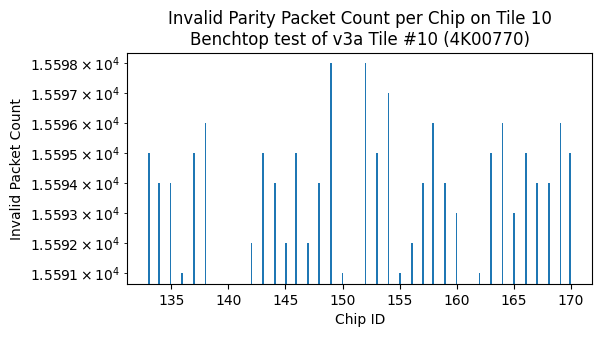

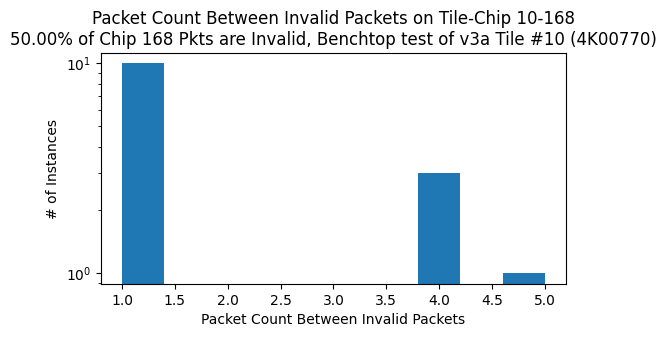

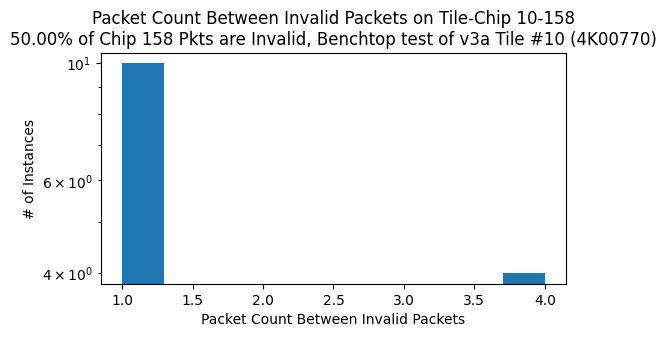

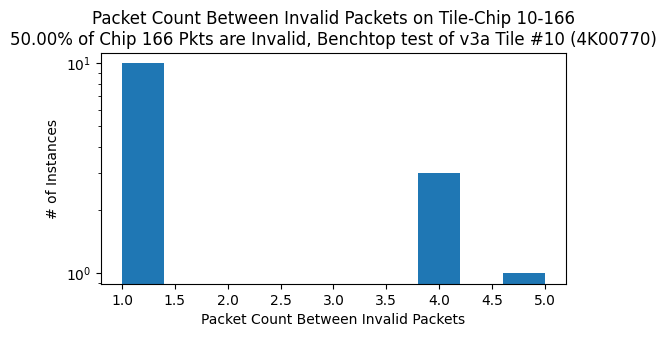

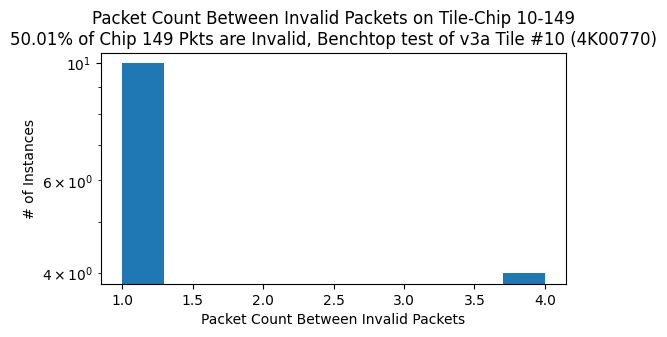

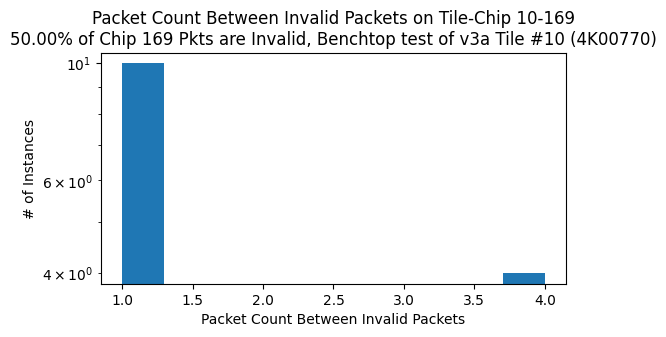

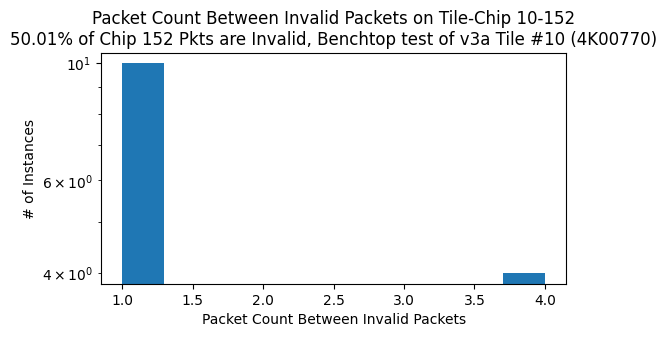

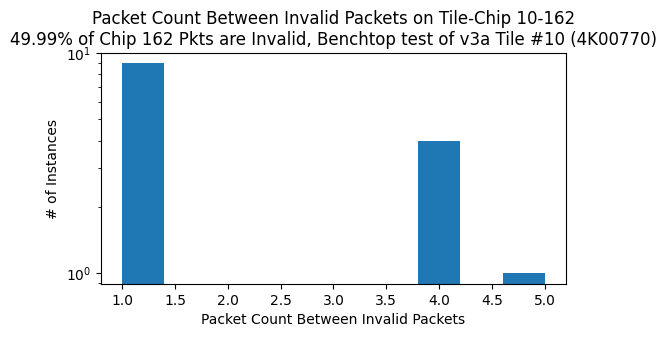

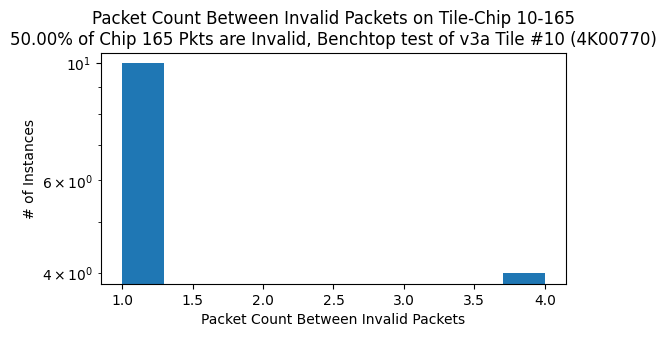

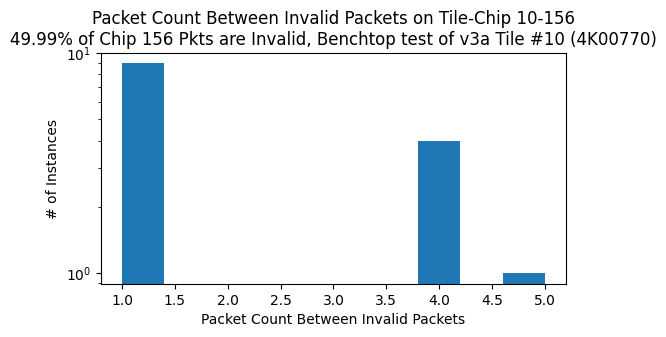

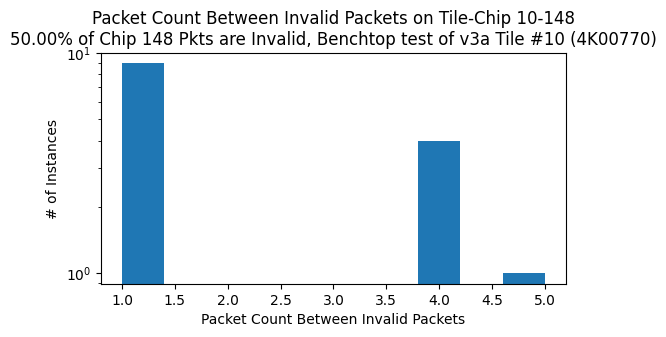

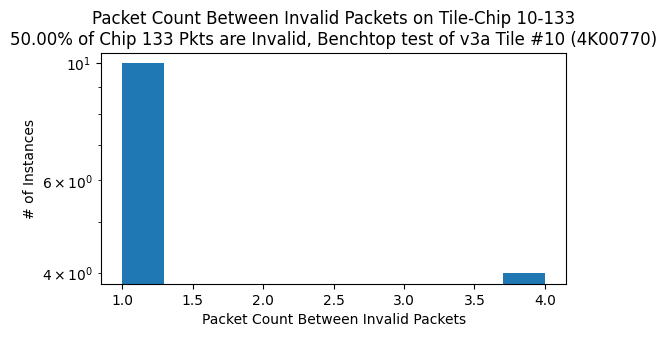

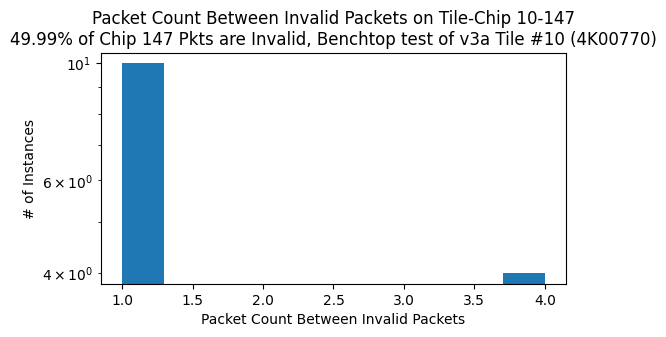

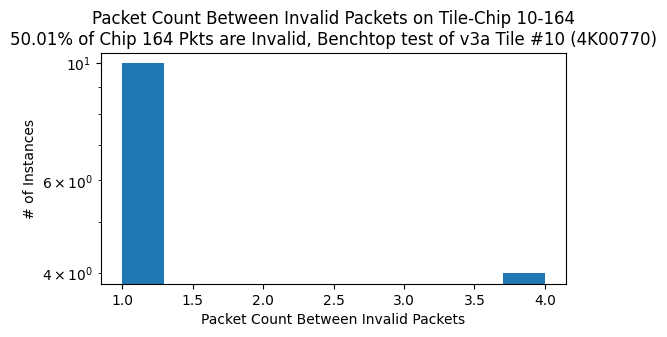

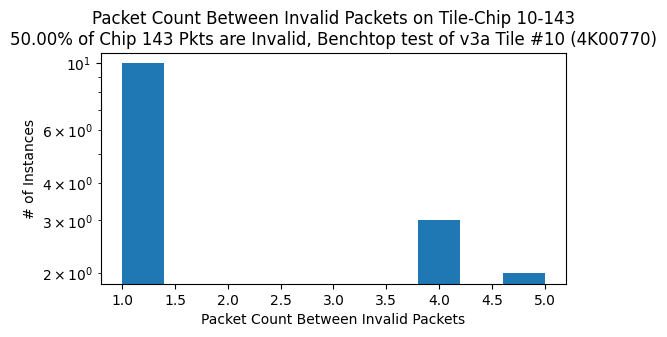

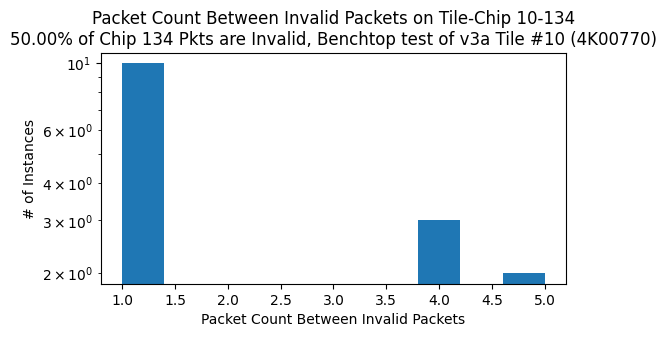

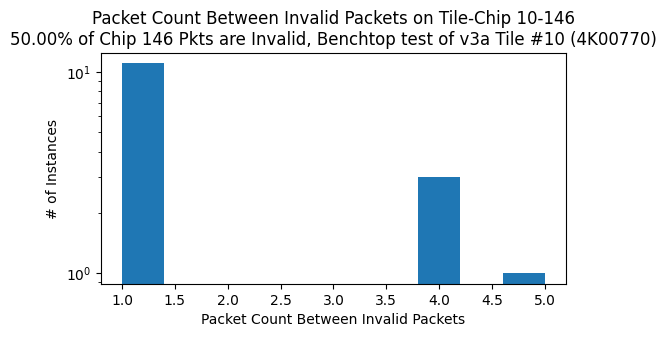

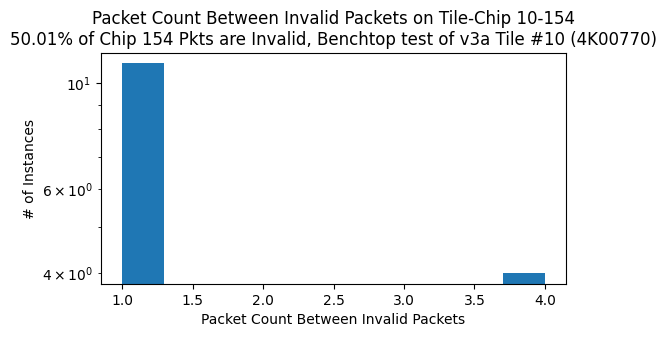

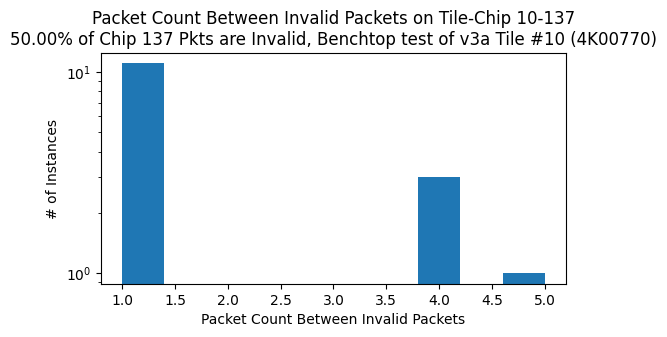

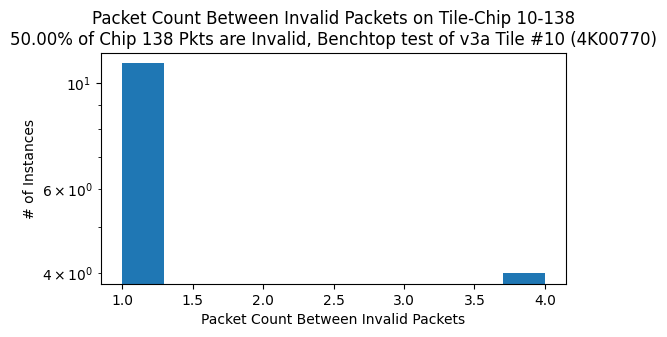

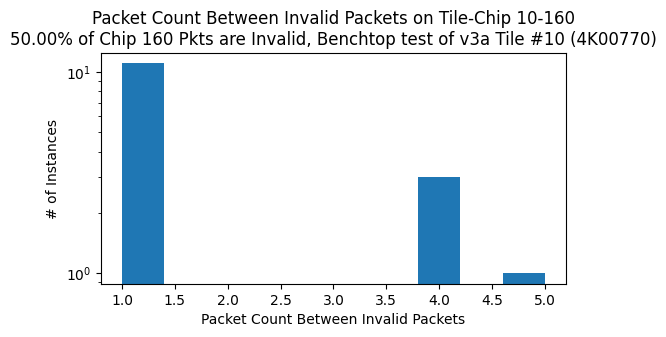

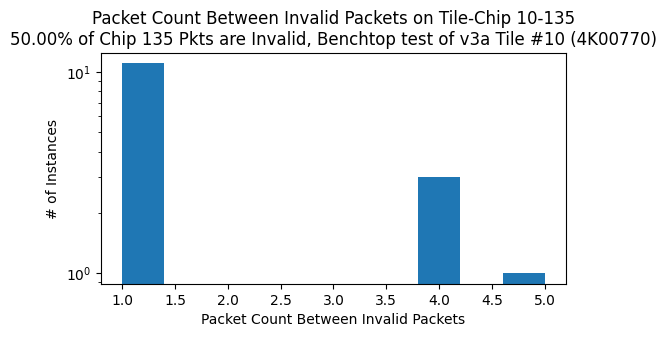

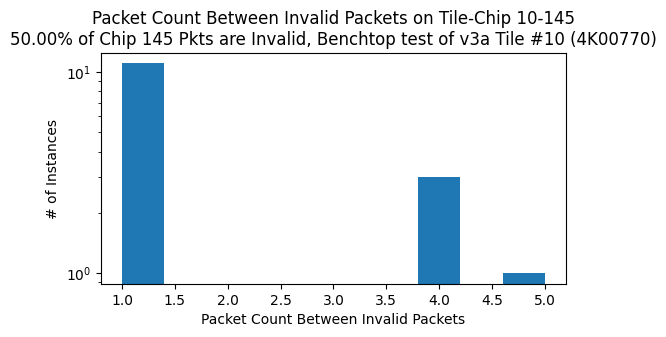

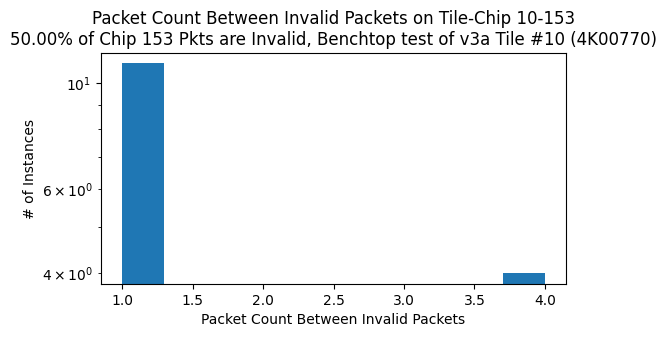

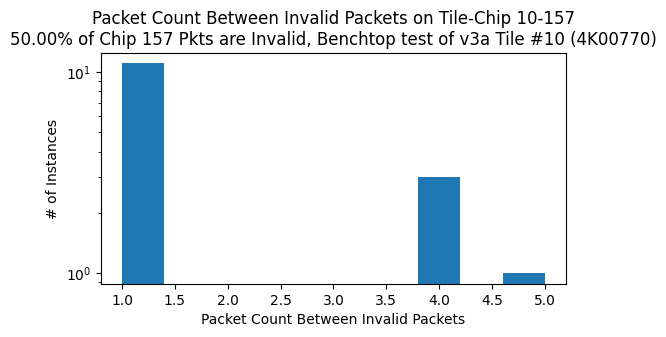

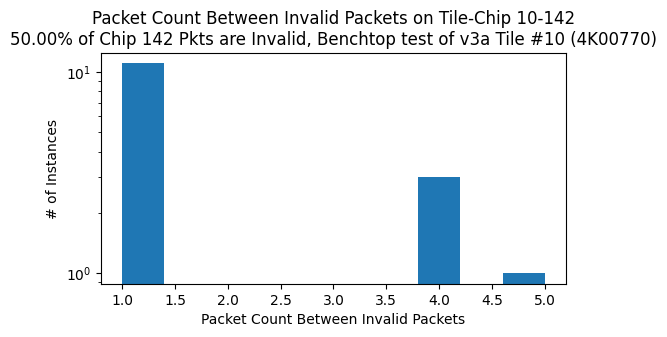

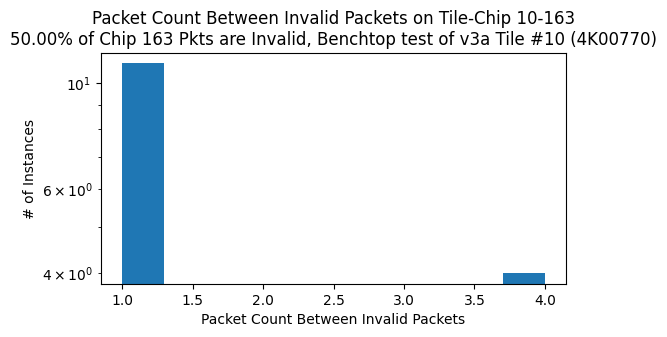

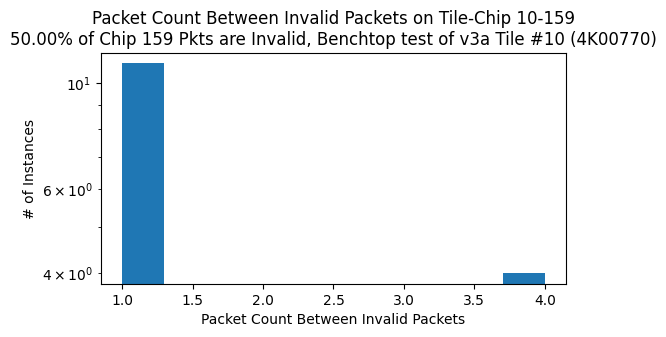

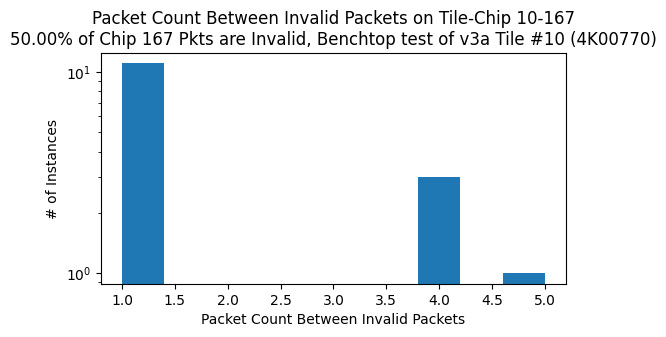

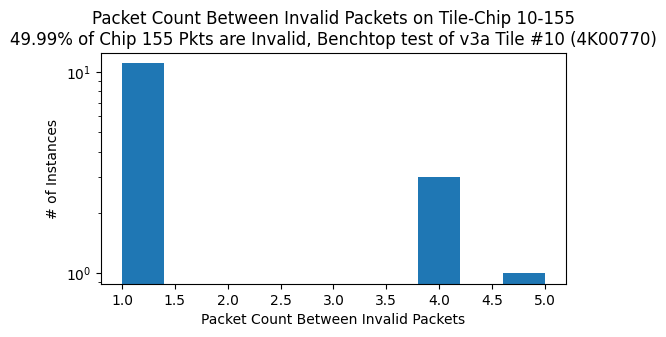

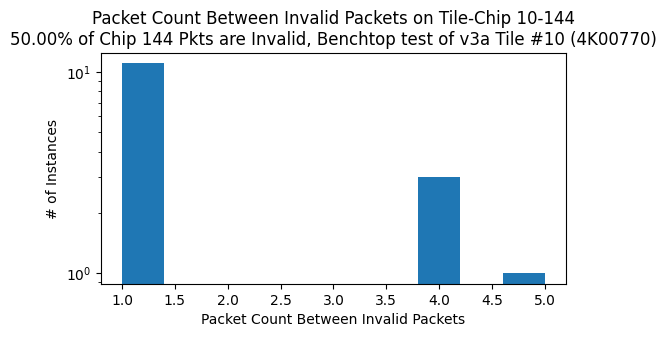

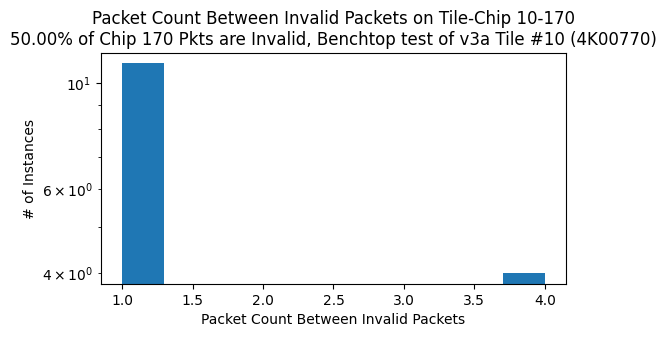

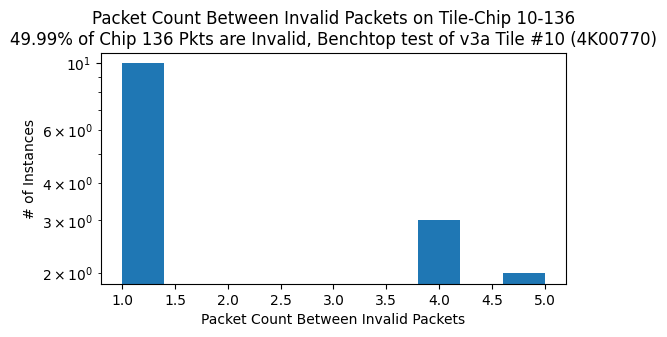

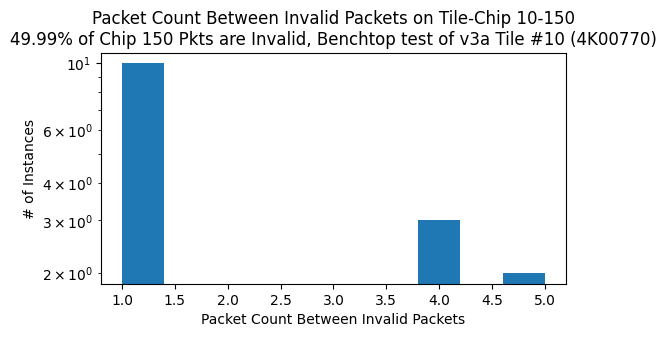

In [10]:
####################
# main
####################


print(f"######################## Run Statistics ############################################")
print(f'\nData File {filename}:')

# import the results dictionary that holds all test results for all tiles at the chmannel level 
#import_results_dictionary()

# get packets from pedestal run data file and check for various attributes
for tile in tiles:
    chip_serial_number = chip_serial_number_list[tile]
    get_data(filename, tile, ig)

#store_results()
